# Time-Frequency Analysis: Seeing Beyond a Global Spectrum

**Question:** how can a representation reveal frequency content that changes over time?

A global Fourier spectrum tells us which frequencies occur over an entire observation, but it loses their timing. This study moves from the waveform to local spectra, then to spectrograms, using Gaussian windows, nearby tones and hyperbolic chirps.

The next study explores multiscale representations; [source separation](03_sparse_source_separation.ipynb) will reuse this STFT directly. All displayed outputs are newly computed using the original course audio files. The methods and parameter comparisons originate in a signal-processing course project at Centrale Lille; see [provenance](../docs/provenance.md).

In [1]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Markdown, Image, Audio

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src/signal_inverse").is_dir():
    raise RuntimeError("Open this notebook from the repository root or notebooks directory.")
sys.path.insert(0, str(ROOT / "src"))
from signal_inverse.datasets import load_inputs
from signal_inverse.experiments import run_time_frequency

inputs = load_inputs(ROOT / "data")
output = ROOT / "results" / "time_frequency"

def figure(name):
    display(Image(filename=str(output / (name + ".png")), width=1000))

def table(rows, columns):
    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    for row in rows:
        values = [f"{row[c]:.3f}" if isinstance(row[c], (float, np.floating)) else str(row[c]) for c in columns]
        lines.append("| " + " | ".join(values) + " |")
    display(Markdown("\n".join(lines)))

print("Inputs: original course image and recordings bundled in data/.")

Inputs: original course image and recordings bundled in data/.


## 1. From samples to spectral content

For $N$ real samples acquired at rate $f_s$, the DFT samples frequencies spaced by $f_s/N$. Hermitian symmetry gives $X[-k]=X[k]^*$: a one-sided representation contains the nonredundant frequencies. Centering the DFT is a change of ordering, not additional information.

Here the displayed DFT is divided by $N$. Input audio is normalized once for analysis. Its global spectrum is compared with six short, Gaussian-windowed segments.

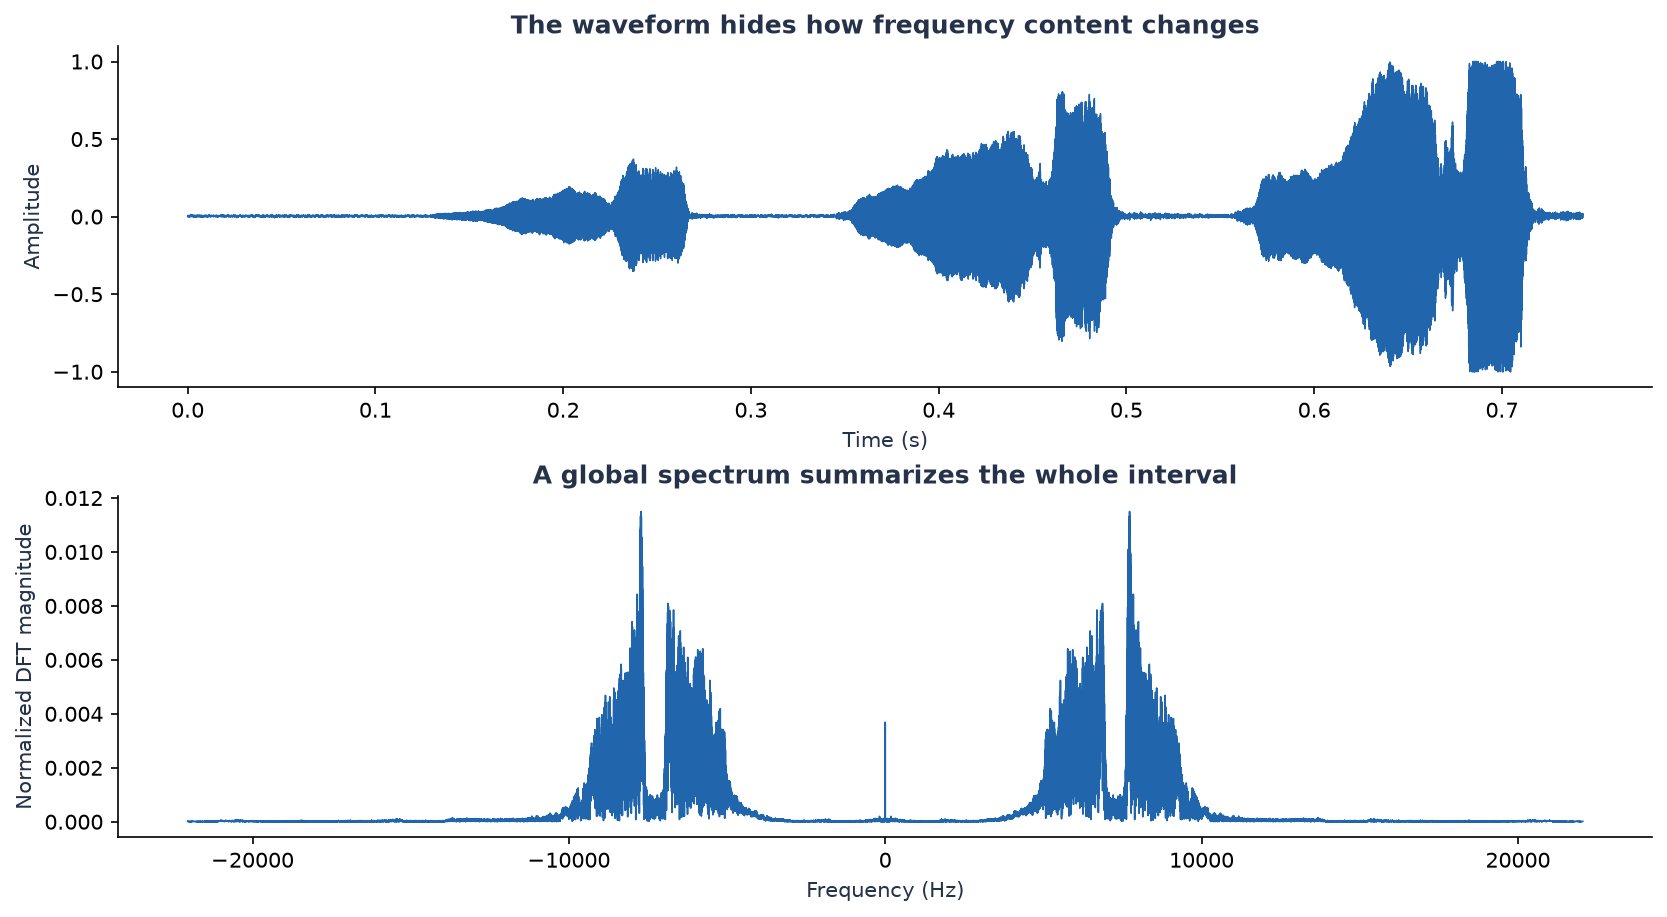

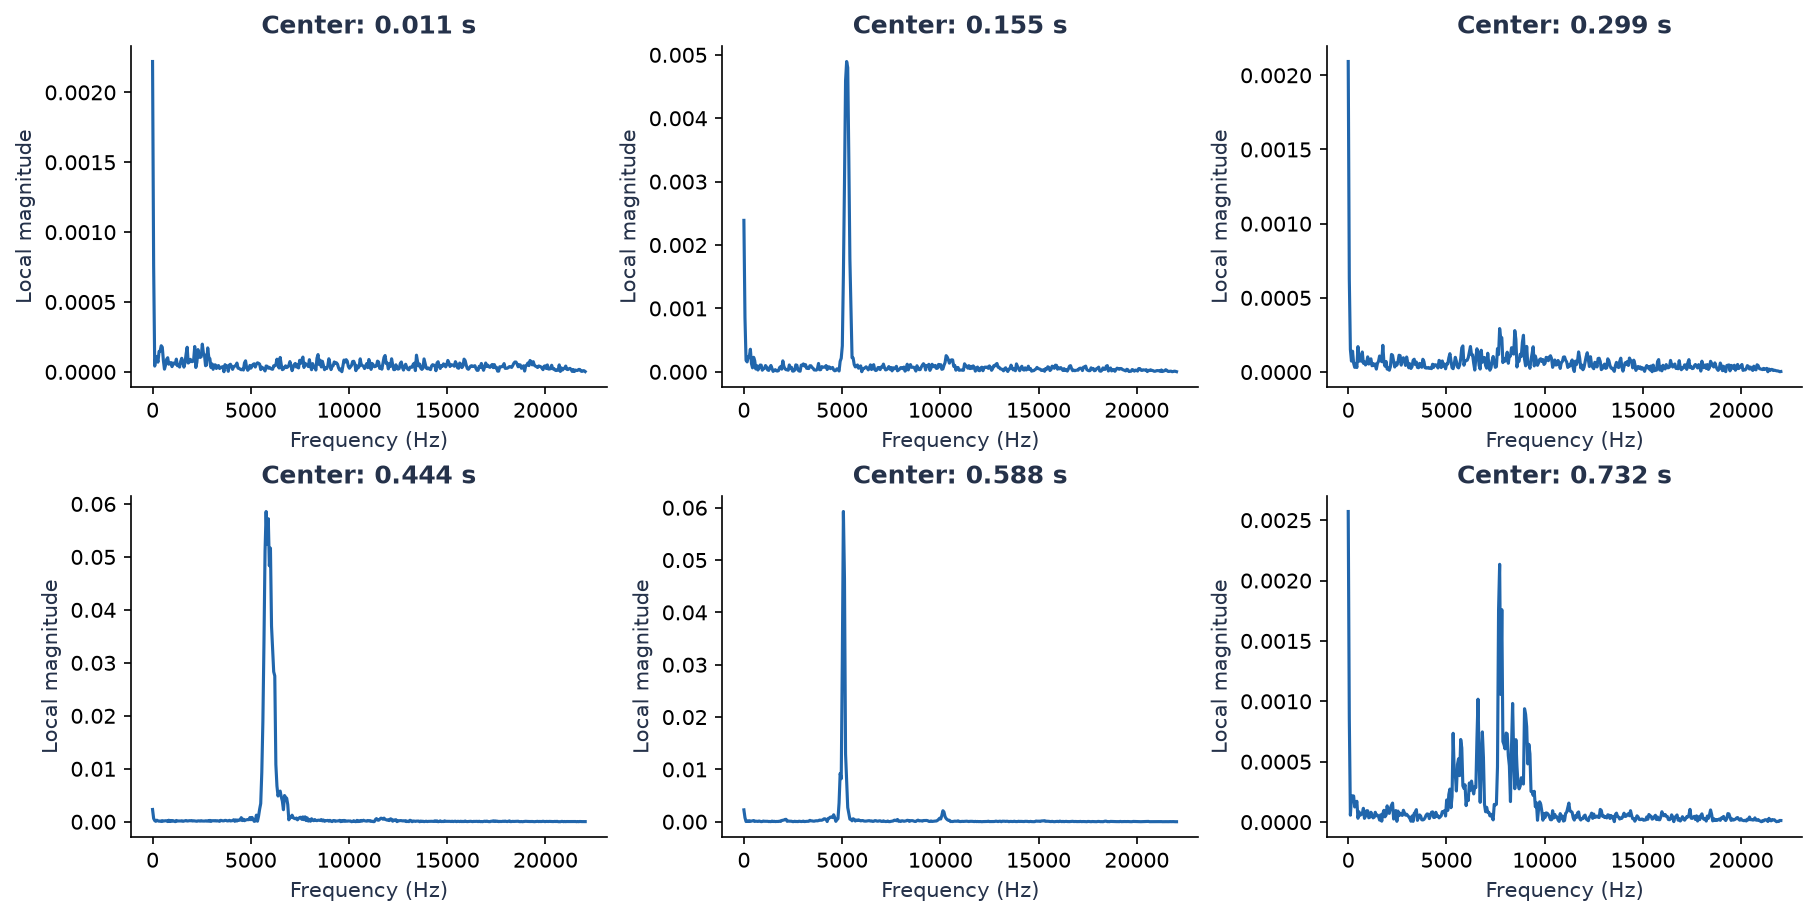

In [2]:
report = run_time_frequency(inputs, output)
figure("global_spectrum")
figure("local_spectra")

## 2. Choosing the scale of observation

The local transform is

$$X_w(\tau,f)=\sum_n x[n]w[n-\tau]e^{-2\pi i f n/f_s}.$$

Gaussian width is expressed in **samples**, consistently in both the time and frequency plots. A wider window separates close stationary frequencies more readily, while averaging rapid temporal changes. Windowing also changes the main-lobe/side-lobe tradeoff; it does not remove every source of leakage.

Local magnitudes cannot simply be summed to recover the global Fourier transform: relative phase, window coverage and time shifts matter.

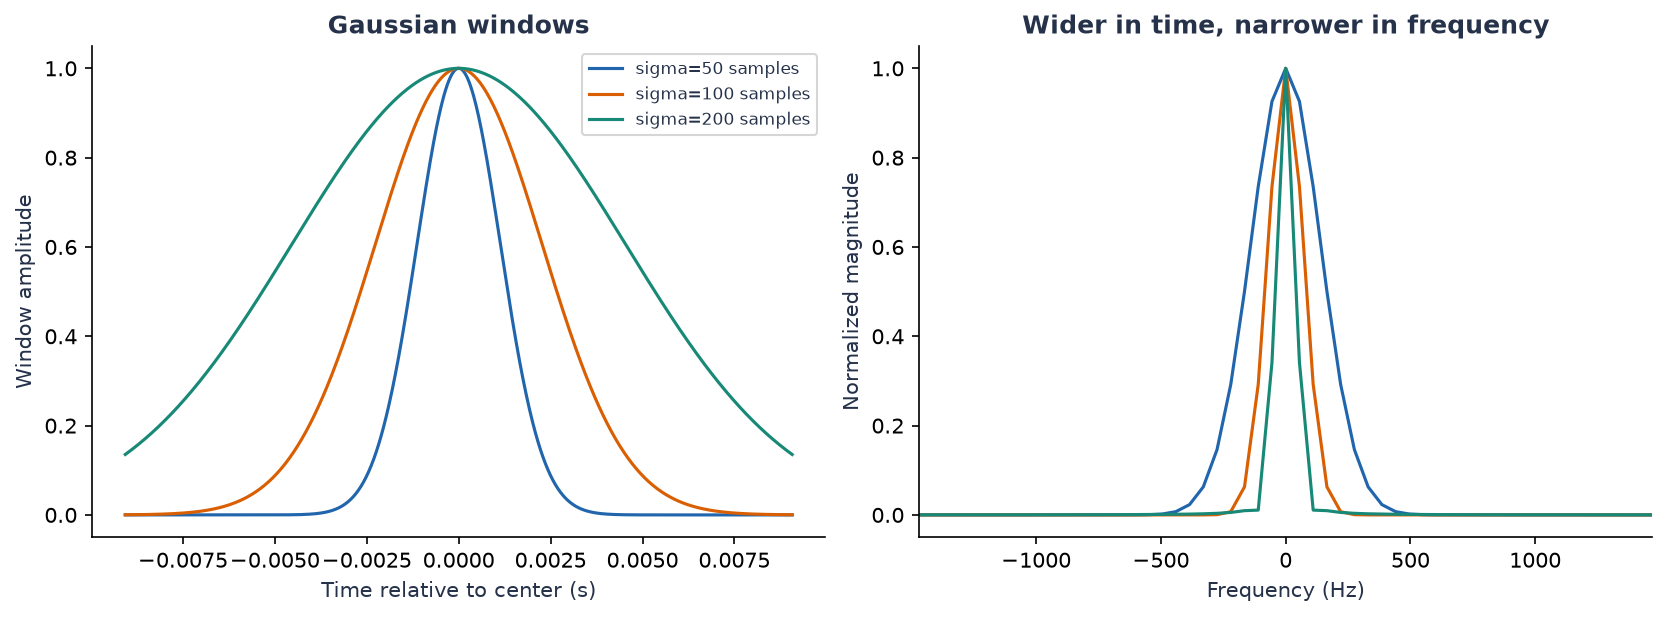

In [3]:
figure("gaussian_tradeoff")

## 3. Can two nearby tones be resolved?

The original `signal_2sinus.mat` file contains two tones at 400 and 424 Hz, sampled at 4096 Hz. We load that file directly, as in the first lab.

The table reports FFT bin spacing, **not a universal resolution limit**. Actual distinguishability also depends on the window's main-lobe width, amplitudes and noise. Spectrograms use consistent dB limits and no independent autoscaling.

| window_samples | duration_ms | bin_spacing_hz | tone_spacing_hz |
| --- | --- | --- | --- |
| 64 | 15.625 | 64.000 | 24.000 |
| 128 | 31.250 | 32.000 | 24.000 |
| 256 | 62.500 | 16.000 | 24.000 |
| 512 | 125.000 | 8.000 | 24.000 |
| 1024 | 250.000 | 4.000 | 24.000 |

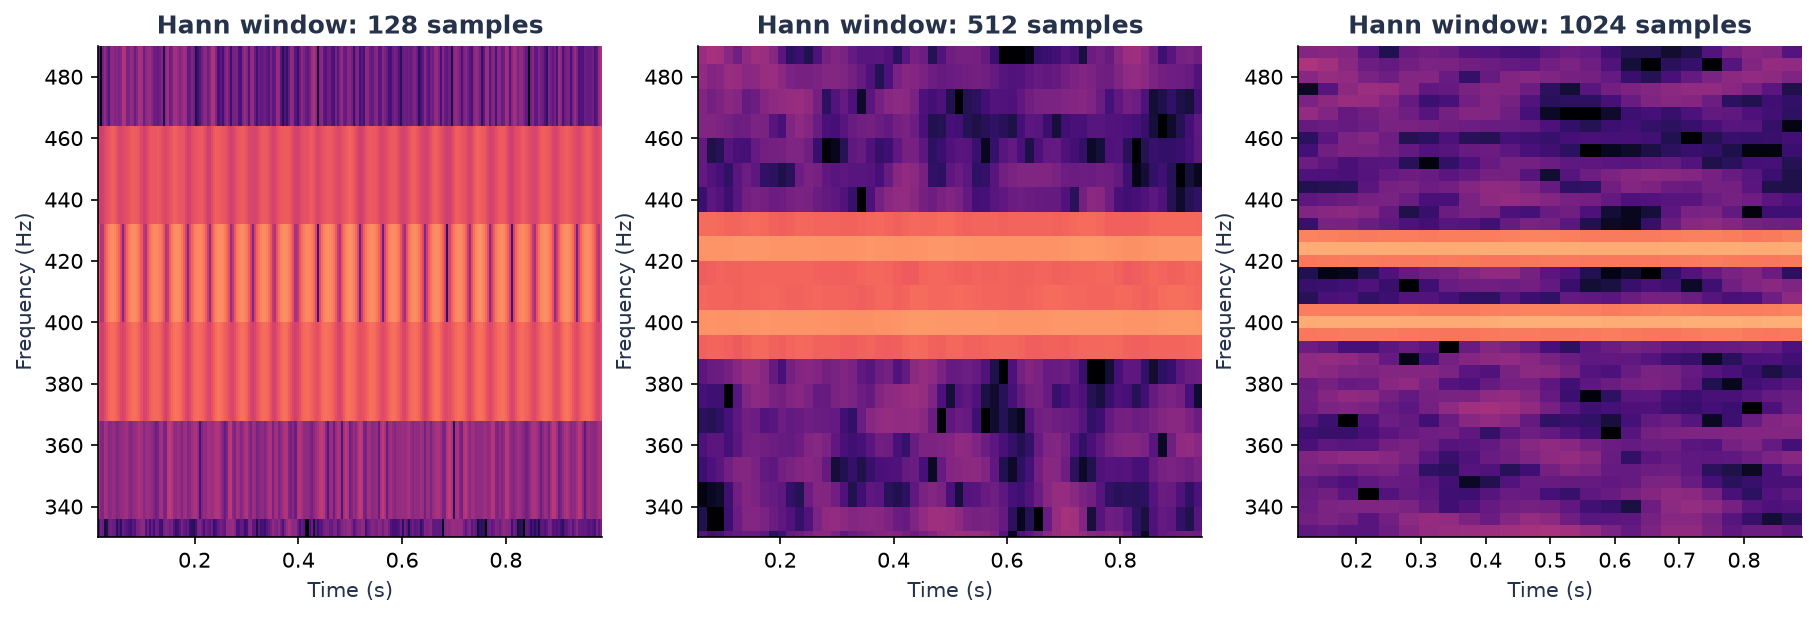

In [4]:
table(report["resolutions"], ["window_samples", "duration_ms", "bin_spacing_hz", "tone_spacing_hz"])
figure("two_tone_resolution")

## 4. A fixed window faces a moving target

Both hyperbolic chirps approach 1650 Hz at three seconds, following the actual terminal frequencies in the original lab. A long window can help distinguish slowly varying components but smear rapidly changing parts. A short window improves temporal localization while broadening frequency peaks.

The PSD spectrogram is shown in dB relative to one squared amplitude unit per Hz. The STFT is a complex transform; the PSD spectrogram is a derived, scaled power representation.

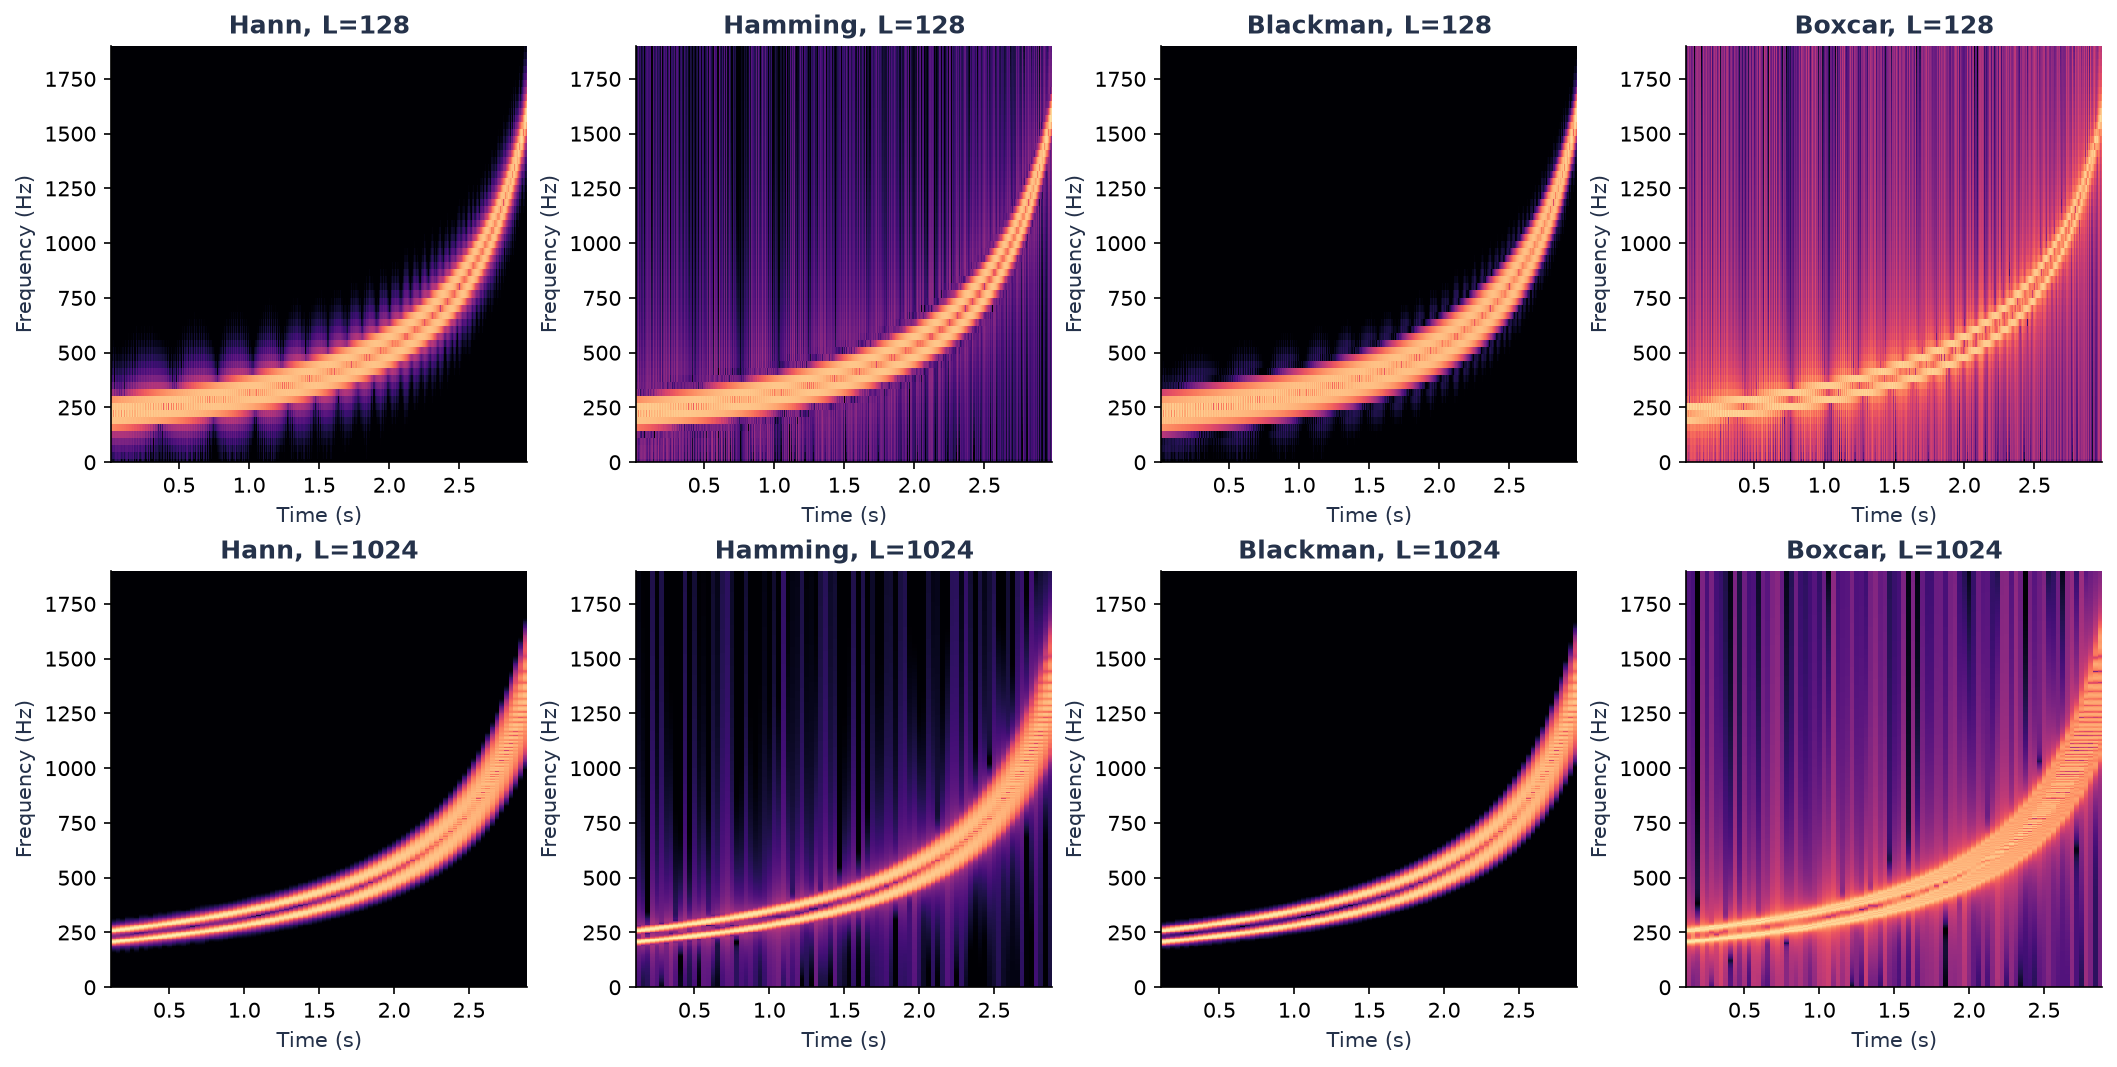

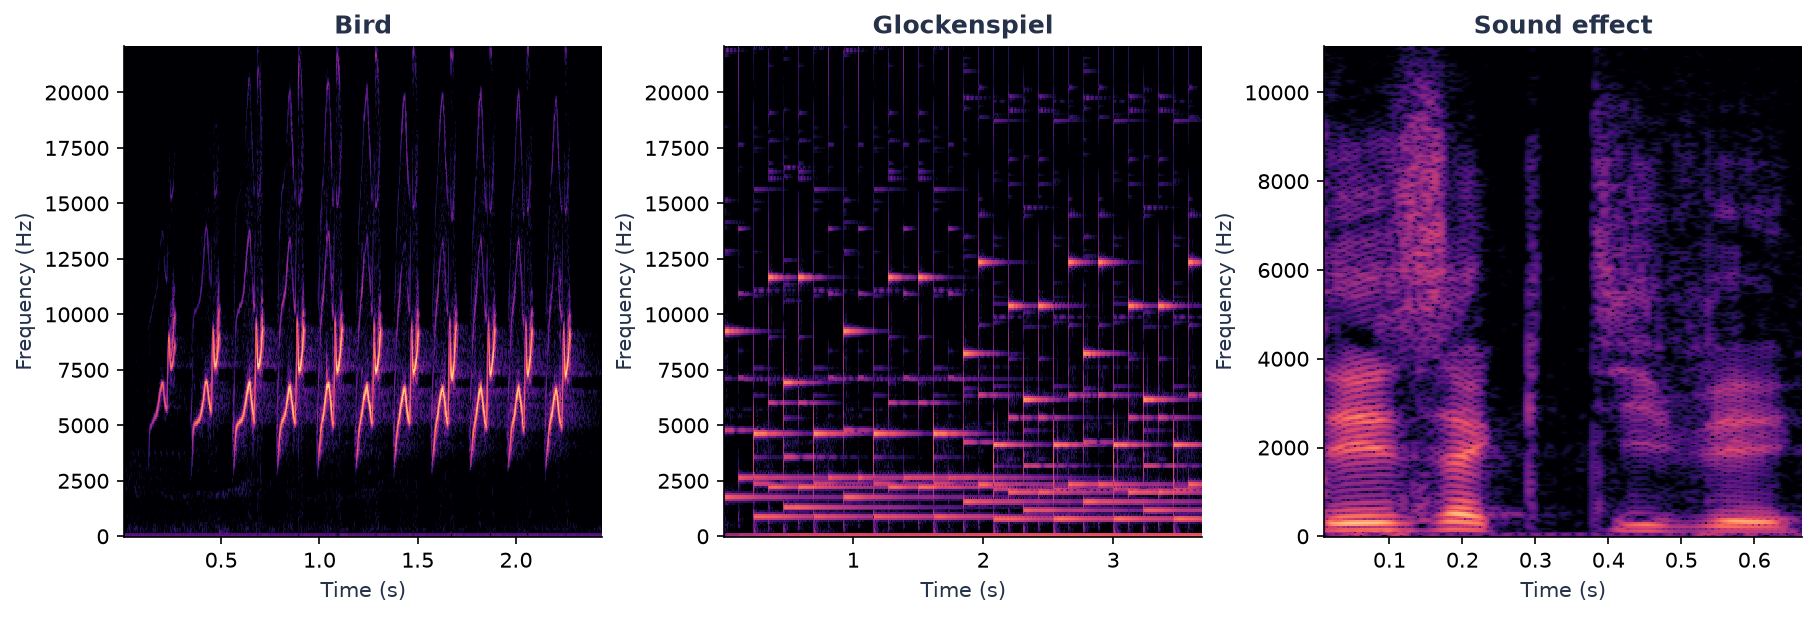

In [5]:
figure("chirp_windows")
figure("audio_signatures")

## 5. Verify reconstruction before editing coefficients

Analysis and synthesis use matched Hann windows, overlap, boundary padding and length trimming. Complete coverage and nonzero overlap-add are needed for reconstruction. These are also prerequisites for later audio separation.

In [6]:
error = report["stft_relative_roundtrip_error"]
assert error < 1e-10
print(f"Relative STFT reconstruction error: {error:.3e}")

Relative STFT reconstruction error: 2.124e-16


## Findings and limits

- Global and local spectra answer different questions: frequency presence versus temporal evolution.
- Increasing window length reduces bin spacing but does not guarantee a better representation of a nonstationary signal.
- Gaussian, Hann, Hamming, Blackman and rectangular windows trade localization against leakage differently.
- Bird, glockenspiel and sound-effect recordings illustrate different spectral signatures; these examples do not establish performance on arbitrary audio.

**Connection:** [wavelet representations](02_wavelet_image_denoising.ipynb) replace a fixed analysis scale with a hierarchy of scales. [Source separation](03_sparse_source_separation.ipynb) uses the STFT to make otherwise entangled mixtures easier to separate.

**Technical references:** [SciPy STFT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.stft.html), [inverse STFT](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.istft.html), and [project bibliography](../REFERENCES.md).